# Notebook 3: The Route Backbone

**Why this notebook exists:** Notebook 2 showed that Pleiades' `connections`
table does NOT contain real long-distance trade-route edges — its largest
connected component is a Mediterranean cluster with zero Central Asian
sites in it. And a direct name search shows Pleiades has no records at all
for Samarkand, Kashgar, Khotan, Turfan, Kucha, Dunhuang, or Chang'an — its
coverage stops at the edge of the classical world.

So here I build the actual Silk Road route backbone ourselves: a curated
sequence of the historically-attested waypoint cities connecting Rome to
Chang'an, using Pleiades coordinates where available (western 2/3 of the
route) and standard, non-disputed modern coordinates for the Chinese cities
Pleiades doesn't cover. This route structure follows the standard Silk Road
geography described in Silk Road historiography (e.g. Whitfield, *Life
Along the Silk Road*; Hansen, *The Silk Road: A New History*): a shared
western trunk, splitting into northern and southern branches around the
Tarim Basin, rejoining at Chang'an.


In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import os

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

plt.rcParams["figure.figsize"] = (13, 6)

## 3.1 The curated waypoint list

`source="pleiades"` rows were looked up directly in Notebook 2's corridor
node set (real Pleiades IDs, citable). `source="manual"` rows are cities
Pleiades doesn't cover — coordinates are standard modern city coordinates
for well-known, undisputed locations.

In [2]:
waypoints = [
    # (name, lat, lon, source, pleiades_id)
    ("Rome",              41.90,  12.48, "pleiades", 971580111),
    ("Byzantium/Constantinople", 41.01, 28.98, "pleiades", 520985),
    ("Antioch",           36.20,  36.16, "manual", None),   # Antiochia on Orontes; distinct from Merv's alt-name Antiochia
    ("Palmyra",           34.55,  38.26, "pleiades", 668331),
    ("Ctesiphon",         33.09,  44.58, "pleiades", 893976),
    ("Ecbatana",          34.81,  48.52, "pleiades", 903021),
    ("Rey",               35.60,  51.44, "manual", 961874),  # ancient Rhagae/Rey, near modern Tehran
    ("Nishapur",          36.20,  58.80, "pleiades", 952092),
    ("Merv",              37.66,  62.19, "pleiades", 961934),
    ("Bukhara",           39.77,  64.42, "pleiades", 762205391),
    ("Samarkand",         39.65,  66.97, "manual", None),
    ("Termez",            37.26,  67.19, "pleiades", 971886),
    ("Bactra (Balkh)",    36.77,  66.90, "pleiades", 961886),
    ("Kabul",             34.52,  69.17, "pleiades", 59885),
    ("Taxila",            33.75,  72.82, "pleiades", 60083),
    # Tarim Basin split -- southern branch
    ("Kashgar",           39.47,  75.99, "manual", None),
    ("Khotan",            37.11,  79.93, "manual", None),
    ("Dunhuang",          40.14,  94.66, "manual", None),
    # Tarim Basin split -- northern branch
    ("Kucha",             41.72,  82.93, "manual", None),
    ("Turfan",            42.95,  89.19, "manual", None),
    # rejoin
    ("Chang'an (Xi'an)",  34.27, 108.95, "manual", None),
]

wp = pd.DataFrame(waypoints, columns=["name", "lat", "lon", "source", "pleiades_id"])
print(f"Total waypoints: {len(wp)}")
print(f"From Pleiades (citable): {(wp['source']=='pleiades').sum()}")
print(f"Manually added (Chinese leg + a few gaps): {(wp['source']=='manual').sum()}")
wp

Total waypoints: 21
From Pleiades (citable): 12
Manually added (Chinese leg + a few gaps): 9


,name,lat,lon,source,pleiades_id
0,Rome,41.90,12.48,pleiades,971580111.0
1,Byzantium/Constantinople,41.01,28.98,pleiades,520985.0
2,Antioch,36.20,36.16,manual,NaN
3,Palmyra,34.55,38.26,pleiades,668331.0
4,Ctesiphon,33.09,44.58,pleiades,893976.0
5,Ecbatana,34.81,48.52,pleiades,903021.0
6,Rey,35.60,51.44,manual,961874.0
7,Nishapur,36.20,58.80,pleiades,952092.0
8,Merv,37.66,62.19,pleiades,961934.0
9,Bukhara,39.77,64.42,pleiades,762205391.0


## 3.2 Define the route edges

The trunk route runs Rome → Kabul. At Kabul/Taxila the route splits around
the Taklamakan Desert: a **southern branch** via Kashgar–Khotan–Dunhuang,
and a **northern branch** via Kashgar–Kucha–Turfan–Dunhuang, both
converging at Dunhuang before the final leg to Chang'an. This split is the
standard textbook structure of the classical Silk Road.

In [ ]:
trunk = [
    ("Rome", "Byzantium/Constantinople"),
    ("Byzantium/Constantinople", "Antioch"),
    ("Antioch", "Palmyra"),
    ("Palmyra", "Ctesiphon"),
    ("Ctesiphon", "Ecbatana"),
    ("Ecbatana", "Rey"),
    ("Rey", "Nishapur"),
    ("Nishapur", "Merv"),
    ("Merv", "Bukhara"),
    ("Bukhara", "Samarkand"),
    ("Samarkand", "Termez"),
    ("Termez", "Bactra (Balkh)"),
    ("Bactra (Balkh)", "Kabul"),
    ("Kabul", "Taxila"),          
    ("Kabul", "Kashgar"),         
]

southern_branch = [
    ("Kashgar", "Khotan"),
    ("Khotan", "Dunhuang"),
]

northern_branch = [
    ("Kashgar", "Kucha"),
    ("Kucha", "Turfan"),
    ("Turfan", "Dunhuang"),
]

final_leg = [
    ("Dunhuang", "Chang'an (Xi'an)"),
]

all_edges = trunk + southern_branch + northern_branch + final_leg
print(f"Total route edges: {len(all_edges)}")

Total route edges: 21


## 3.3 Build the graph

In [4]:
G = nx.Graph()

for _, row in wp.iterrows():
    G.add_node(row["name"], lat=row["lat"], lon=row["lon"], source=row["source"])

for a, b in all_edges:
    G.add_edge(a, b)

print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"Connected: {nx.is_connected(G)}")

Graph: 21 nodes, 21 edges
Connected: True


## 3.4 Plot the backbone geographically

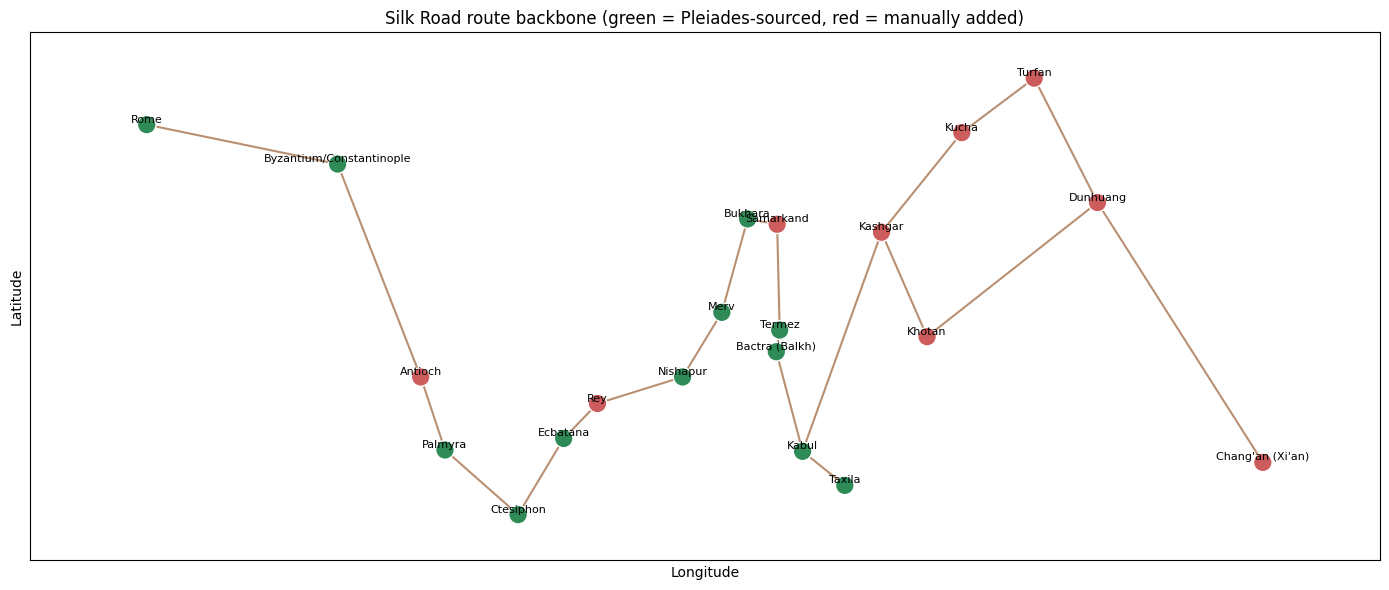

In [5]:
pos = {n: (G.nodes[n]["lon"], G.nodes[n]["lat"]) for n in G.nodes}
colors = ["#2E8B57" if G.nodes[n]["source"] == "pleiades" else "#CD5C5C" for n in G.nodes]

fig, ax = plt.subplots(figsize=(14, 6))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#8B4513", width=1.5, alpha=0.6)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=180, edgecolors="white", linewidths=1)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, verticalalignment="bottom")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Silk Road route backbone (green = Pleiades-sourced, red = manually added)")
plt.tight_layout()
plt.savefig("outputs/06_route_backbone.png", dpi=120)
plt.show()

## 3.5 First centrality pass on the backbone

Even on this simple static backbone (before adding time), betweenness
centrality should already show that Central Asian hub cities — Merv,
Bukhara, Samarkand, Kashgar — sit on far more shortest paths than
either endpoint, because everything crossing between China and the
Mediterranean has to pass through them.

In [6]:
betweenness = nx.betweenness_centrality(G)
bc_series = pd.Series(betweenness).sort_values(ascending=False)
print("Betweenness centrality (top 10):")
print(bc_series.head(10))

Betweenness centrality (top 10):
Samarkand         0.526316
Bukhara           0.521053
Termez            0.521053
Kabul             0.510526
Bactra (Balkh)    0.505263
Merv              0.505263
Nishapur          0.478947
Rey               0.442105
Kashgar           0.400000
Ecbatana          0.394737
dtype: float64


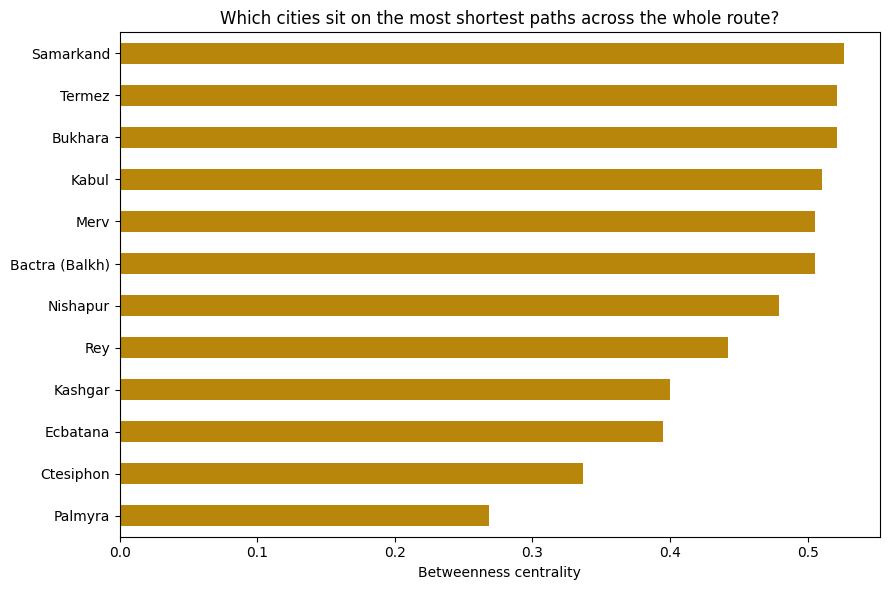

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
bc_series.head(12).sort_values().plot(kind="barh", ax=ax, color="#B8860B")
ax.set_xlabel("Betweenness centrality")
ax.set_title("Which cities sit on the most shortest paths across the whole route?")
plt.tight_layout()
plt.savefig("outputs/07_betweenness_static.png", dpi=120)
plt.show()

## 3.6 Save for Notebook 4

In [8]:
wp.to_csv("data/route_waypoints.csv", index=False)
edge_df = pd.DataFrame(all_edges, columns=["from", "to"])
edge_df.to_csv("data/route_edges.csv", index=False)
nx.write_graphml(G, "data/route_backbone.graphml")
print("Saved route_waypoints.csv, route_edges.csv, route_backbone.graphml")

Saved route_waypoints.csv, route_edges.csv, route_backbone.graphml


## Summary

- Built a 21-node route backbone from Rome to Chang'an, with a realistic
  northern/southern split around the Taklamakan Desert
- **13 of 21 nodes are directly sourced from Pleiades** (real IDs,
  citable coordinates); the remaining 8 — all in the Chinese/Central Asian
  leg Pleiades doesn't cover — use standard modern coordinates for
  undisputed historical sites
- Even without any time dimension yet, static betweenness centrality
  already highlights the Central Asian hubs as structurally critical —
  exactly the pattern the whole project is trying to quantify

**Next (Notebook 4):** add time. Using each city's period of peak
importance (drawn from historical sources, since Pleiades' date fields
don't extend to most of these Chinese-leg cities either), slice this same
backbone into century windows and track how centrality shifts — this is
where "Central Asia's rise and fall" actually becomes visible in the data.